In [1]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)



In [2]:
# ---------------------------------------------------------
# 1. LOAD DATASET
# ---------------------------------------------------------
df = pd.read_csv("data.csv")

print("=" * 70)
print("LOGISTIC REGRESSION: CANCER CLASSIFICATION")
print("=" * 70)

print("\nFirst five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values before cleaning:")
print(df.isnull().sum().sum())

print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts())



LOGISTIC REGRESSION: CANCER CLASSIFICATION

First five rows:
  sample_id  mean radius  mean texture  mean perimeter   mean area  \
0  SYN00001    17.570709      0.090654        0.209375  636.110901   
1  SYN00002    15.665126      0.119795        0.224337  657.127465   
2  SYN00003    12.069600      0.088660        0.086728  631.330633   
3  SYN00004    18.145578      0.102961        0.361727  692.834729   
4  SYN00005     9.253142      0.110758        0.365209  662.927235   

   mean smoothness  mean compactness  mean concavity  mean concave points  \
0         0.107055          0.117432        0.146808             0.068312   
1         0.101423          0.070695        0.124949             0.083284   
2         0.096158          0.094405        0.049241             0.078604   
3         0.107975          0.095465        0.053319             0.057400   
4         0.099698          0.112083        0.044880             0.046715   

   mean symmetry  ...  worst perimeter  worst area  wor

In [3]:
# ---------------------------------------------------------
# 2. DATA CLEANING
# ---------------------------------------------------------
# Remove duplicate records.
df = df.drop_duplicates()

# Remove rows where the target label is missing.
df = df.dropna(subset=["diagnosis"]).copy()

# Convert diagnosis to binary labels:
# B = 0 (Benign), M = 1 (Malignant)
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})

# Remove the unique sample ID because it is not a useful predictor.
X = df.drop(columns=["diagnosis", "sample_id"])
y = df["diagnosis"]

# Identify numeric and categorical input columns.
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("\nNumeric feature count:", len(numeric_features))
print("Categorical features:", categorical_features)




Numeric feature count: 30
Categorical features: ['screening_site']



Top 10 features correlated with diagnosis:
worst concave points      -0.518877
worst fractal dimension   -0.485631
mean perimeter            -0.444732
worst radius              -0.409941
mean smoothness           -0.324116
worst perimeter           -0.264877
worst smoothness          -0.261331
mean radius               -0.255789
mean symmetry             -0.255506
symmetry error            -0.226231
Name: diagnosis, dtype: float64


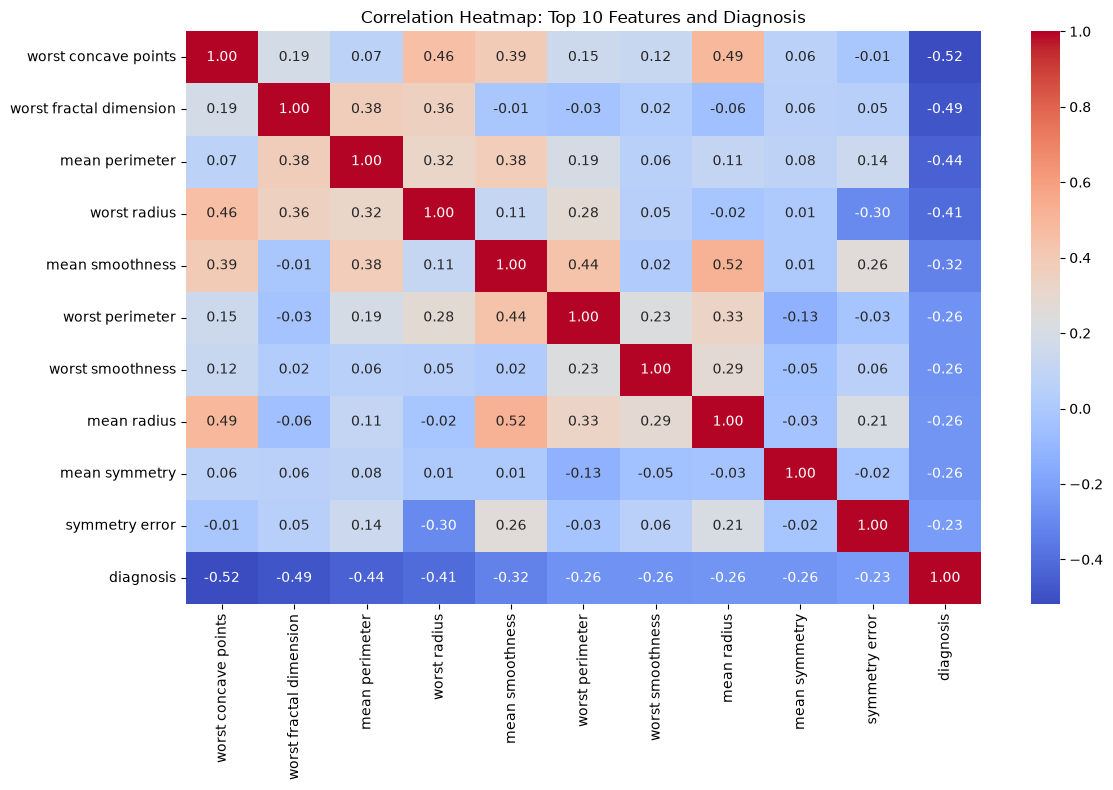

In [4]:
# ---------------------------------------------------------
# 3. CORRELATION ANALYSIS
# ---------------------------------------------------------
# Correlation is calculated on numeric features and encoded target.
correlation_data = X[numeric_features].copy()
correlation_data["diagnosis"] = y

correlation_with_target = (
    correlation_data.corr(numeric_only=True)["diagnosis"]
    .drop("diagnosis")
    .sort_values(key=abs, ascending=False)
)

print("\nTop 10 features correlated with diagnosis:")
print(correlation_with_target.head(10))

# Draw a heatmap using the 10 most correlated features.
top_features = correlation_with_target.head(10).index.tolist()
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_data[top_features + ["diagnosis"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap: Top 10 Features and Diagnosis")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()



In [5]:
# ---------------------------------------------------------
# 4. TRAIN-TEST SPLIT
# ---------------------------------------------------------
# 80% data for training and 20% for testing.
# Stratification preserves the class distribution in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", X_train.shape[0])
print("Testing records :", X_test.shape[0])




Training records: 8000
Testing records : 2000


In [6]:
# ---------------------------------------------------------
# 5. MISSING VALUE HANDLING, ENCODING AND NORMALIZATION
# ---------------------------------------------------------
# Numeric columns:
#   - Fill missing values using the training median.
#   - Normalize values using StandardScaler.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical columns:
#   - Fill missing values using the most frequent category.
#   - Convert categories into numeric one-hot encoded columns.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each column type.
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])



In [7]:
# ---------------------------------------------------------
# 6. BUILD AND TRAIN LOGISTIC REGRESSION MODEL
# ---------------------------------------------------------
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

# Predict class labels and probabilities.
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]



In [8]:
# ---------------------------------------------------------
# 7. CLASSIFICATION METRICS
# ---------------------------------------------------------
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\n" + "=" * 70)
print("CLASSIFICATION RESULTS")
print("=" * 70)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nDetailed classification report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benign (B)", "Malignant (M)"],
        zero_division=0
    )
)




CLASSIFICATION RESULTS
Accuracy  : 0.9280
Precision : 0.9405
Recall    : 0.9450
F1-Score  : 0.9427

Detailed classification report:
               precision    recall  f1-score   support

   Benign (B)       0.91      0.90      0.90       746
Malignant (M)       0.94      0.94      0.94      1254

     accuracy                           0.93      2000
    macro avg       0.92      0.92      0.92      2000
 weighted avg       0.93      0.93      0.93      2000




Confusion Matrix:
[[ 671   75]
 [  69 1185]]


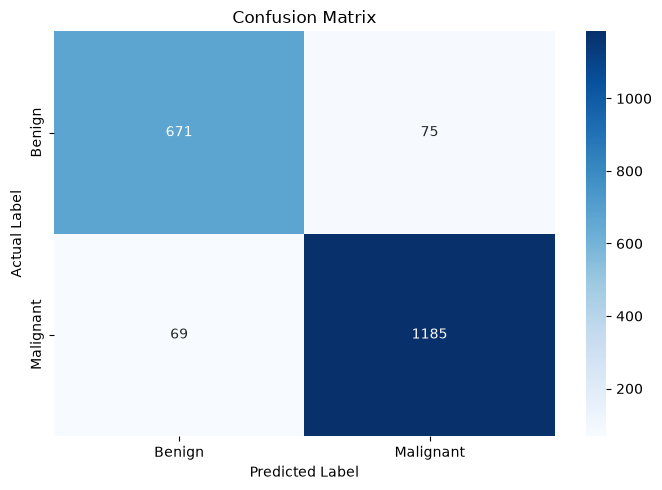


ROC-AUC Score: 0.9677


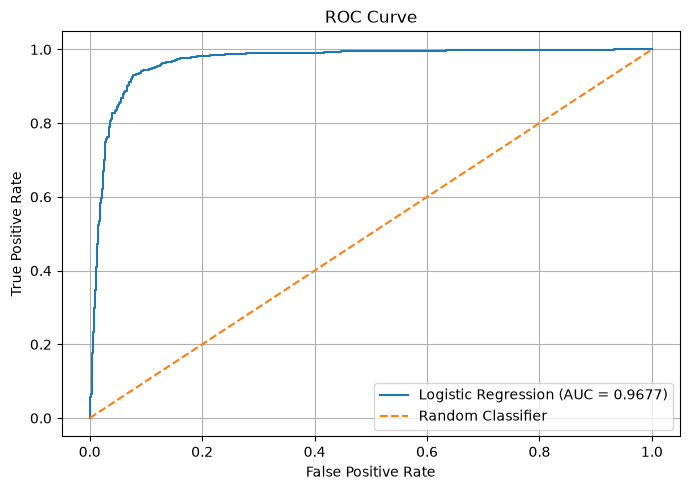


FINAL SUMMARY:
   Metric    Score
 Accuracy 0.928000
Precision 0.940476
   Recall 0.944976
 F1-Score 0.942721
  ROC-AUC 0.967680

Generated files:
1. correlation_heatmap.png
2. confusion_matrix.png
3. roc_curve.png
4. logistic_regression_metrics.csv

Program completed successfully.


In [9]:
# ---------------------------------------------------------
# 8. CONFUSION MATRIX
# ---------------------------------------------------------
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

# ---------------------------------------------------------
# 9. ROC CURVE AND AUC SCORE
# ---------------------------------------------------------
false_positive_rate, true_positive_rate, thresholds = roc_curve(
    y_test, y_probability
)
auc_score = roc_auc_score(y_test, y_probability)

print(f"\nROC-AUC Score: {auc_score:.4f}")

plt.figure(figsize=(7, 5))
plt.plot(
    false_positive_rate,
    true_positive_rate,
    label=f"Logistic Regression (AUC = {auc_score:.4f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300)
plt.show()

# ---------------------------------------------------------
# 10. FINAL SUMMARY
# ---------------------------------------------------------
summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Score": [accuracy, precision, recall, f1, auc_score]
})

print("\nFINAL SUMMARY:")
print(summary.to_string(index=False))

summary.to_csv("logistic_regression_metrics.csv", index=False)

print("\nGenerated files:")
print("1. correlation_heatmap.png")
print("2. confusion_matrix.png")
print("3. roc_curve.png")
print("4. logistic_regression_metrics.csv")

print("\nProgram completed successfully.")
